# Maxwell 3D few-mode fiber
A step-index optical fiber that guides exactly two mode groups, the fundamental LP01
and the two-lobed LP11, with light launched into it as the fiber's own modes and
followed for 350 um along the core.

The fiber is a 2.5 um-radius core of index 1.48 in a cladding of 1.45 at 1.55 um, so its
normalised frequency is V = 2 pi a NA / lambda = 3.0: LP01 and the LP11 pair are guided
and nothing else. The index contrast is about six times a telecom fiber's, which brings
the LP01-LP11 beat length ``lambda / (n_01 - n_11)`` down to about a hundred micrometres,
three periods inside the domain. The core is 6% elliptical, its long axis along x. Real
fibers are slightly elliptical, and here the ellipticity also fixes the orientation of
the two LP11 modes: in a perfectly round core they are degenerate and any pair of
orientations is as good as any other. The simulation axes are
  * z = along the fiber (propagation),
  * x = the long axis of the core,
  * y = the short axis.

The launch is the fiber's own modes: the engine solves the full-vector modes of the
(x, y) cross-section of the simulation grid when the run starts, with its
pseudo-spectral mode solver, and drives the ones asked for one way along the fiber.
A source is a specification -- where, which polarization, which order, how long a
drive -- and the run reports the modes it solved and their effective indices.

Two runs. First LP01 alone: a guided mode must travel unchanged, so its transverse
profile is the same at every plane and the phase it accumulates per micrometre gives an
effective index that must agree with the one the engine solved. That is the test of the
launch and of the geometry. Then LP01 and LP11 together, with equal power and in phase
where the drive ends: the two modes accumulate phase at different rates, so the intensity
centroid swings from one side of the core to the other and back with the beat length
``lambda / (n_01 - n_11)``. The beat length predicted from the two solved indices against
the one measured from the field is the headline comparison. The beat is interference of
two waves whose indices differ by about 0.014, carried over 300 wavelengths.

Then the coupling itself: a thinner single-mode fiber is butt-joined to the few-mode
fiber with its axis shifted sideways, and its own mode is launched towards the joint.
The mismatch there splits the light between LP01, LP11 and radiation in proportions set
by the shift, and the two guided parts beat downstream. The first two runs supply the
LP01 and LP11 fields themselves, so the field after the joint is decomposed onto them and
the LP11 fraction read off, for three shifts.

The core is a curved surface, so it is given to the solver as a voxel array painted four
times finer than the simulation grid across the fiber. The service averages each block of
fine cells into one simulation voxel: the core edge becomes graded voxels rather than a
staircase, and the mode solver and the propagation see the same graded core.

Size: 5 solves, the largest 74.26 Mvoxel including boundaries, 3.87 GB of memory (service estimate).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Ellipse
from scipy.optimize import curve_fit

from wavesimpro import Medium, Setup, VoxelArray, create_mode_source, create_monitor, submit
from wsutils import output_dir

NAME = "mx_fewmode_fiber"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>

### Parameters (edit these to rescale)

In [2]:
wavelength = 1.55   # μm
pixel_size = 0.175  # grid spacing (μm); 6 points per wavelength in the core

n_core = 1.48
n_clad = 1.45

a_core = 2.5        # mean core radius (μm): V = 3.0, two guided mode groups
ellipticity = 0.06  # (long - short) / mean axis; long axis along x
a_x = a_core * (1 + ellipticity / 2)
a_y = a_core * (1 - ellipticity / 2)

n_xy = 115          # transverse voxels; odd, so the fiber axis runs through voxel centres
nz = 2000           # voxels along the fiber: 350 μm, about three beat lengths
sim_xy = n_xy * pixel_size
sim_z = nz * pixel_size

# The core is painted ``refine`` times finer than the grid across the fiber, over a block
# of ``block_n`` simulation voxels on a side centred on the axis; the service averages each
# refine x refine x 1 block of cells into one voxel.
refine = 4
block_n = 41        # 7.2 μm: the core with 1 μm of cladding around it

# Each mode is launched one way by driving a length of fiber with the mode's own phase,
# so the backward wave cancels. The drive ends at z_drive_end.
z_drive_end = 12.0  # μm from the input face
drive_length = 5.0  # μm of fiber driven

# Absorbing boundary, 4 wavelengths on every face: the modes leave through z, and what a
# joint radiates reaches the x and y faces at grazing incidence, where a thin ramp would
# send it back into the cladding.
boundary_widths = [4.0 * wavelength] * 3

# Transverse planes (μm from the input face) returned in full for the profile checks.
z_planes = [20, 48, 76, 104, 132, 340]

i_drive_end = int(round(z_drive_end / pixel_size))
mvox = n_xy * n_xy * nz / 1e6
V = 2 * np.pi * a_core * np.sqrt(n_core ** 2 - n_clad ** 2) / wavelength
print(f"Fiber: core {a_x:.3f} x {a_y:.3f} um (V = {V:.2f}), {sim_z:.0f} um long")
print(f"Grid: {n_xy} x {n_xy} x {nz} = {mvox:.1f} Mvoxel without boundaries  (px={pixel_size} um)")

Fiber: core 2.575 x 2.425 um (V = 3.00), 350 um long
Grid: 115 x 115 x 2000 = 26.4 Mvoxel without boundaries  (px=0.175 um)


### Build the geometry: the core on a fine grid

In [3]:
def core_layer(ax, ay, x0=0.0):
    """One transverse layer of the fine grid: an elliptical core of semi-axes (ax, ay)
    centred at (x0, 0) in cladding; the layer is block_n*refine cells on a side."""
    fine = pixel_size / refine
    c = (np.arange(block_n * refine) + 0.5) * fine - block_n * pixel_size / 2
    X, Y = np.meshgrid(c, c, indexing="ij")
    inside = ((X - x0) / ax) ** 2 + (Y / ay) ** 2 <= 1.0
    return np.where(inside, n_core ** 2, n_clad ** 2).astype(np.complex64)


def extrude(layer, n_layers):
    """The same layer repeated along z."""
    return np.repeat(layer[:, :, None], n_layers, axis=2)


fiber_layer = core_layer(a_x, a_y)
fill = (fiber_layer.real - n_clad ** 2).sum() / (n_core ** 2 - n_clad ** 2) * (pixel_size / refine) ** 2
print(f"Core area painted: {fill:.3f} um^2 against pi*a_x*a_y = {np.pi * a_x * a_y:.3f} um^2")

Core area painted: 19.585 um^2 against pi*a_x*a_y = 19.617 um^2


### Sources: the engine solves and launches the fiber's modes

In [4]:
# The cut is the (x, y) layer where the drive ends. At run start the engine solves the
# full-vector modes of that layer of the voxelised fiber; among those with E along x,
# order 0 is LP01 and order 1 the LP11 whose two lobes lie along x, the core's long axis
# (order 2 has them along y). The y-polarised modes are the same by symmetry.
def fiber_mode(name, order):
    return create_mode_source(name=name, axis="z", plane_index=i_drive_end, direction=+1,
                              polarization="x", order=order, drive_length_um=drive_length,
                              engine_solver="ps_operator")


print(f"Mode sources end at z = {i_drive_end * pixel_size:.2f} um after {drive_length} um "
      f"of drive towards +z")

Mode sources end at z = 12.07 um after 5.0 um of drive towards +z


### Monitors: the axial plane and a few transverse planes

In [5]:
# Monitors crop the result server-side, so only these slices are transferred instead of
# the full volume. Voxel index i on an n-voxel axis sits at (i + 0.5 - n/2)*px in
# domain-centred world coordinates. The axial monitor is a slab three voxels thick in y
# through the fiber axis, the whole length; each transverse monitor is one voxel thick.
monitor_names = ["axial"] + [f"plane_{z_plane}" for z_plane in z_planes]
monitors = [create_monitor(name="axial", center_x=0.0, center_y=0.0, center_z=0.0,
                           size_x=sim_xy, size_y=3 * pixel_size, size_z=sim_z)]
for z_plane in z_planes:
    k = int(round(z_plane / pixel_size - 0.5))
    monitors.append(create_monitor(name=f"plane_{z_plane}", center_x=0.0, center_y=0.0,
                                   center_z=(k + 0.5 - nz / 2) * pixel_size,
                                   size_x=sim_xy, size_y=sim_xy, size_z=pixel_size))

### Run: submit the setup, read the monitors and the solved modes

In [6]:
# A setup is one document: the domain and grid, the cladding as background, the core as
# a voxel array on its fine grid, the sources and the monitors. ``submit`` uploads the
# array, saves the document and starts the run. Every solve is its own project, in a
# folder named after this script.
cladding = Medium("cladding", n_clad)


def fiber_setup(tag, sources, permittivity_fine):
    """The fiber with this fine-grid core and these sources."""
    fine = pixel_size / refine
    setup = Setup(wavelength, pixel_size, (n_xy, n_xy, nz), boundary_widths=boundary_widths,
                  background=cladding, name=f"{NAME} {tag}", folder=NAME)
    setup.add(VoxelArray(array=permittivity_fine, name="core", n=cladding,
                         pixel_size=(fine, fine, pixel_size), subpixel=True),
              *sources, *monitors)
    return setup


def solve(tag, sources, permittivity_fine):
    """Run the fiber with these sources and return the monitor fields, keyed by monitor
    name, the solved modes and the run's iteration count and time. The fields are kept in
    OUTPUT_DIR under the tag."""
    setup = fiber_setup(tag, sources, permittivity_fine)
    run = submit(setup, sampling_warnings=False)   # 6 points per wavelength by design
    print(f"Submitted {tag}: project {run.project_id}, version {run.version_id}")
    run.wait()
    print(f"Time {run.elapsed:.1f} s; Iterations {run.iterations}; Residual {run.residual_norm}")

    # One field per monitor, in the order the monitors were added, and the record of the
    # modes solved.
    fields = dict(zip(monitor_names, run.get_monitors()))
    np.savez(f"{OUTPUT_DIR}/{tag}_monitors.npz", **fields)
    modes = {m["name"]: m for m in run.mode_sources()}
    with open(f"{OUTPUT_DIR}/{tag}_modeSources.json", "w") as f:
        json.dump(modes, f, indent=1)
    for name, m in modes.items():
        share = m["eShare"]
        print(f"  {name}: neff = {m['neff']['re']:.5f}; E energy {share['x']:.1%} along x, "
              f"{share['y']:.1%} along y, {share['z']:.1%} longitudinal")
    return dict(fields=fields, modes=modes, iterations=run.iterations, seconds=run.elapsed)

### Reading the field

In [7]:
# Ex is the dominant component of the launched modes. The axial monitor gives Ex on the
# (x, z) plane through the fiber axis; the x and z coordinates are those of the voxel
# centres the monitor returned.
def axial_field(run):
    ex = run["fields"]["axial"][0]
    return ex[:, ex.shape[1] // 2, :]


def coordinates(field):
    x = (np.arange(field.shape[0]) + 0.5 - field.shape[0] / 2) * pixel_size
    z = (np.arange(field.shape[1]) + 0.5) * pixel_size
    return x, z


def transverse_profiles(run):
    """The full field (3, nx, ny) on each transverse plane, keyed by z in μm."""
    planes = {z_plane: run["fields"][f"plane_{z_plane}"] for z_plane in z_planes}
    return {z_plane: p if p.ndim == 3 else p[..., 0] for z_plane, p in planes.items()}


def profile_difference(e, e_ref):
    """Relative rms difference between two fields after scaling e_ref by the one complex
    factor (amplitude and phase) that best matches them."""
    s = np.vdot(e_ref, e) / np.vdot(e_ref, e_ref)
    return float(np.sqrt(np.sum(np.abs(e - s * e_ref) ** 2) / np.sum(np.abs(e) ** 2)))


z_clear = z_drive_end + 3.0   # the fit windows start here, clear of the drive


def figure(run, title, trace):
    """The axial intensity, the trace drawn by ``trace(ax, x, z)`` under it, and the
    transverse planes in a row."""
    ex = axial_field(run)
    x, z = coordinates(ex)
    intensity = np.abs(ex) ** 2
    intensity /= intensity.max()
    fig = plt.figure(figsize=(12, 8.5))
    gs = GridSpec(3, len(z_planes), figure=fig, height_ratios=[1.6, 1.0, 1.4])
    ax1 = fig.add_subplot(gs[0, :])
    im = ax1.imshow(intensity, cmap="inferno", origin="lower", aspect="auto",
                    extent=[0, sim_z, -sim_xy / 2, sim_xy / 2], norm=LogNorm(vmin=1e-4, vmax=1.0))
    ax1.axvline(z_drive_end, color="cyan", lw=0.6, alpha=0.6)
    for z_plane in z_planes:
        ax1.axvline(z_plane, color="white", lw=0.4, alpha=0.4, ls="--")
    ax1.set_ylabel(r"$x~(\mu m)$")
    ax1.set_title(title)
    fig.colorbar(im, ax=ax1, fraction=0.015, pad=0.01).ax.set_title(r"$|E_x|^2$")
    ax2 = fig.add_subplot(gs[1, :], sharex=ax1)
    trace(ax2, x, z)
    ax2.set_xlim(0, sim_z)
    ax2.set_xlabel(r"$z~(\mu m)$ -- along the fiber")
    ax2.grid(alpha=0.3)
    ax2.legend(loc="upper right", fontsize=8)
    profiles = transverse_profiles(run)
    peak = max(np.sum(np.abs(p) ** 2, axis=0).max() for p in profiles.values())
    half = sim_xy / 2
    for j, (z_plane, p) in enumerate(profiles.items()):
        ax = fig.add_subplot(gs[2, j])
        ax.imshow(np.sum(np.abs(p) ** 2, axis=0).T / peak, cmap="inferno", origin="lower",
                  extent=[-half, half, -half, half], vmin=0, vmax=1)
        ax.add_patch(Ellipse((0, 0), 2 * a_x, 2 * a_y, fill=False, ec="cyan", lw=0.5, alpha=0.6))
        ax.set_xlim(-6, 6)
        ax.set_ylim(-6, 6)
        ax.set_title(f"z = {z_plane} um", fontsize=9)
        ax.set_xlabel(r"$x~(\mu m)$", fontsize=8)
        if j == 0:
            ax.set_ylabel(r"$y~(\mu m)$", fontsize=8)
        else:
            ax.set_yticklabels([])
    fig.tight_layout()
    return fig

### Run 1: LP01 alone travels unchanged

In [8]:
lp01 = solve("lp01", [fiber_mode("LP01", 0)], extrude(fiber_layer, nz))
neff_01_solved = lp01["modes"]["LP01"]["neff"]["re"]

  [!] Mode source 'LP01': linear absorbing layers at the two z ends (35 and 35 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 27 px (4.81 um) per end.


Submitted lp01: project 90005f96-f760-4ea2-970a-f67d739e1850, version 74e326ba-df82-40ff-aad8-bdce5e236f32

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 90005f96-f760-4ea2-970a-f67d739e1850
  Version   : 74e326ba-df82-40ff-aad8-bdce5e236f32
  Command   : 64ae85fb-53c7-4b71-a6fc-6583467772d8
  Mode      : Maxwell (vectorial)
  Domain    : 115x115x2000 voxels  lambda=1.55 um  dx=0.175 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 254.1 s; Iterations 1548; Residual 9.986937e-07
  LP01: neff = 1.46951; E energy 99.5% along x, 0.0% along y, 0.5% longitudinal


### Run 1 checks: the profile at every plane, the phase advance against the solved index

LP01 effective index: 1.46951 solved by the engine, 1.46951 from the phase advance (+3.0e-06)
  phase residual rms 0.0024 rad; on-axis intensity ripple 1.40% peak to peak
  profile against z = 20 um: 0.0e+00 at 20 um, 3.2e-04 at 48 um, 4.0e-04 at 76 um, 5.0e-04 at 104 um, 5.8e-04 at 132 um, 6.4e-04 at 340 um


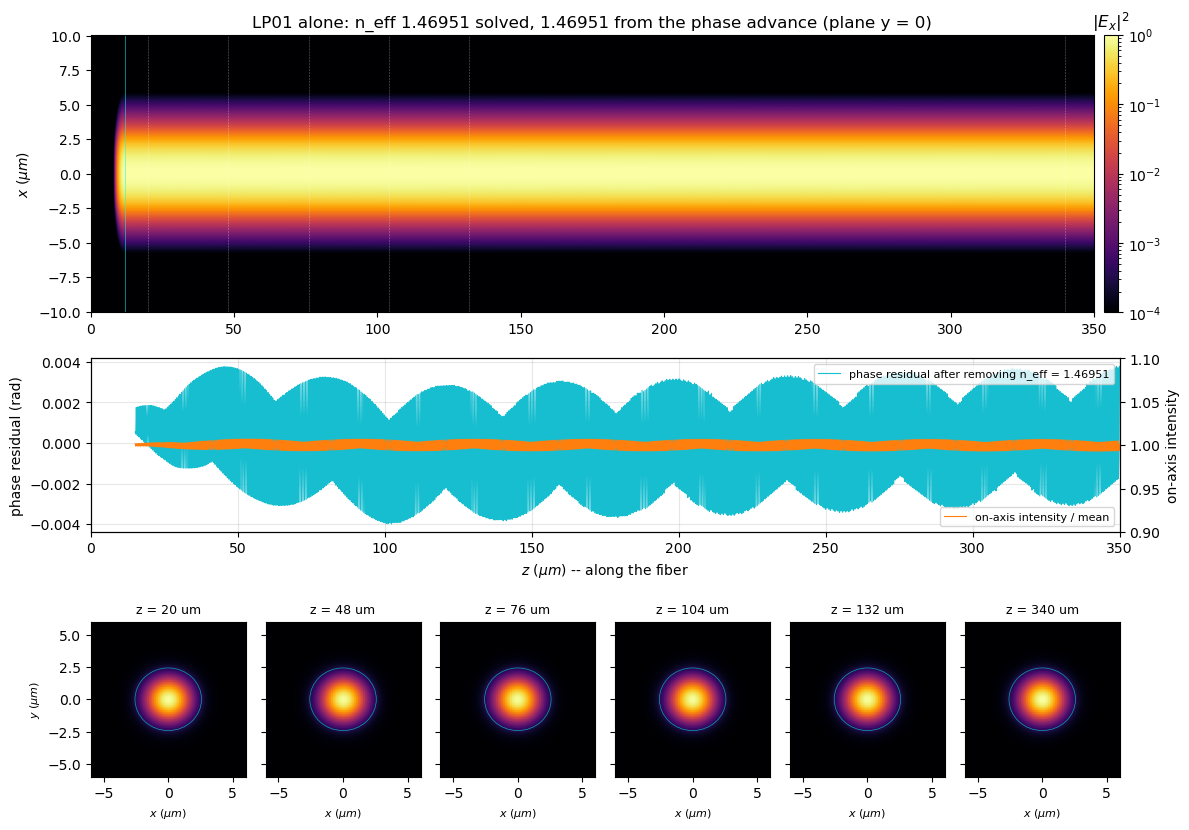

In [9]:
# On the fiber axis Ex(z) of a single guided mode is A*exp(i*2*pi*n_eff*z/lambda): the
# slope of its unwrapped phase gives n_eff, and what is left after the straight line is
# removed shows anything else present. Its intensity along the axis must be flat; a
# ripple at lambda/(2*n_eff) would be a reflection, a slower beat, light outside the core.
ex = axial_field(lp01)
x, z = coordinates(ex)
on_axis = ex[np.argmin(np.abs(x)), :]
keep = z > z_clear
phase = np.unwrap(np.angle(on_axis[keep]))
slope, offset = np.polyfit(z[keep], phase, 1)
neff_01_measured = slope * wavelength / (2 * np.pi)
phase_residual = phase - (slope * z[keep] + offset)
axis_intensity = np.abs(on_axis[keep]) ** 2
ripple = float((axis_intensity.max() - axis_intensity.min()) / axis_intensity.mean())
print(f"LP01 effective index: {neff_01_solved:.5f} solved by the engine, "
      f"{neff_01_measured:.5f} from the phase advance "
      f"({neff_01_measured - neff_01_solved:+.1e})")
print(f"  phase residual rms {np.sqrt(np.mean(phase_residual ** 2)):.4f} rad; "
      f"on-axis intensity ripple {ripple:.2%} peak to peak")

# The transverse field at each plane against the first one, after one amplitude and
# phase factor: a mode travelling unchanged leaves only the grid's rounding here.
profiles = transverse_profiles(lp01)
reference = profiles[z_planes[0]]
differences = {z_plane: profile_difference(p, reference) for z_plane, p in profiles.items()}
print(f"  profile against z = {z_planes[0]} um: "
      + ", ".join(f"{d:.1e} at {z_plane} um" for z_plane, d in differences.items()))

with open(f"{OUTPUT_DIR}/results_lp01.json", "w") as f:
    json.dump(dict(neff_solved=neff_01_solved, neff_measured=neff_01_measured,
                   phase_residual_rms_rad=float(np.sqrt(np.mean(phase_residual ** 2))),
                   axis_intensity_ripple=ripple, profile_difference=differences,
                   e_share=lp01["modes"]["LP01"]["eShare"], iterations=lp01["iterations"],
                   seconds=lp01["seconds"]), f, indent=1)


def lp01_trace(ax, x, z):
    ax.plot(z[keep], phase_residual, color="tab:cyan", lw=0.8,
            label=f"phase residual after removing n_eff = {neff_01_measured:.5f}")
    ax.set_ylabel("phase residual (rad)")
    ax2 = ax.twinx()
    ax2.plot(z[keep], axis_intensity / axis_intensity.mean(), color="tab:orange", lw=0.8,
             label="on-axis intensity / mean")
    ax2.set_ylim(0.9, 1.1)
    ax2.set_ylabel("on-axis intensity")
    ax2.legend(loc="lower right", fontsize=8)


fig = figure(lp01, f"LP01 alone: n_eff {neff_01_solved:.5f} solved, {neff_01_measured:.5f} "
             f"from the phase advance (plane y = 0)", lp01_trace)
fig.savefig(f"{OUTPUT_DIR}/mx_fewmode_fiber_lp01.png", dpi=200, bbox_inches="tight")
fig.savefig(f"{OUTPUT_DIR}/mx_fewmode_fiber_lp01.pdf", bbox_inches="tight")
plt.show()
plt.close("all")

### Run 2: LP01 and LP11 together beat

In [10]:
beat = solve("beat", [fiber_mode("LP01", 0), fiber_mode("LP11", 1)], extrude(fiber_layer, nz))
neff_01, neff_11 = (beat["modes"][name]["neff"]["re"] for name in ("LP01", "LP11"))
L_beat_predicted = wavelength / (neff_01 - neff_11)
print(f"Beat length from the solved indices: {L_beat_predicted:.2f} um")

  [!] Mode source 'LP01': linear absorbing layers at the two z ends (35 and 35 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 27 px (4.81 um) per end.
  [!] Mode source 'LP11': linear absorbing layers at the two z ends (35 and 35 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 27 px (4.81 um) per end.


Submitted beat: project 07c76277-3807-4529-943d-1995f90c1dc7, version e700b212-30bc-4d7d-9a69-0c30669cedff

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 07c76277-3807-4529-943d-1995f90c1dc7
  Version   : e700b212-30bc-4d7d-9a69-0c30669cedff
  Command   : bd4f8bab-7626-4365-b6b0-6e32b86b2f9b
  Mode      : Maxwell (vectorial)
  Domain    : 115x115x2000 voxels  lambda=1.55 um  dx=0.175 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 215.0 s; Iterations 1621; Residual 9.530423e-07
  LP01: neff = 1.46951; E energy 99.5% along x, 0.0% along y, 0.5% longitudinal
  LP11: neff = 1.45569; E energy 98.4% along x, 0.2% along y, 1.5% longitudinal
Beat length from the solved indices: 112.14 um


### Run 2 checks: the centroid's swing against the predicted beat length

Beat length: 112.14 um from the solved indices, 112.13 +/- 0.00 um from the centroid (+0.01% prediction error)
  centroid swings +/- 1.249 um about x = +0.000 um, fit residual 0.004 um rms; on-axis intensity ripple 1.39%
  run 2 minus run 1: LP01 left over 5.1e-07 of the energy; LP11 n_eff 1.45569 from its phase advance (+2.2e-06 against the solved); beat length from the two measured indices 112.13 um


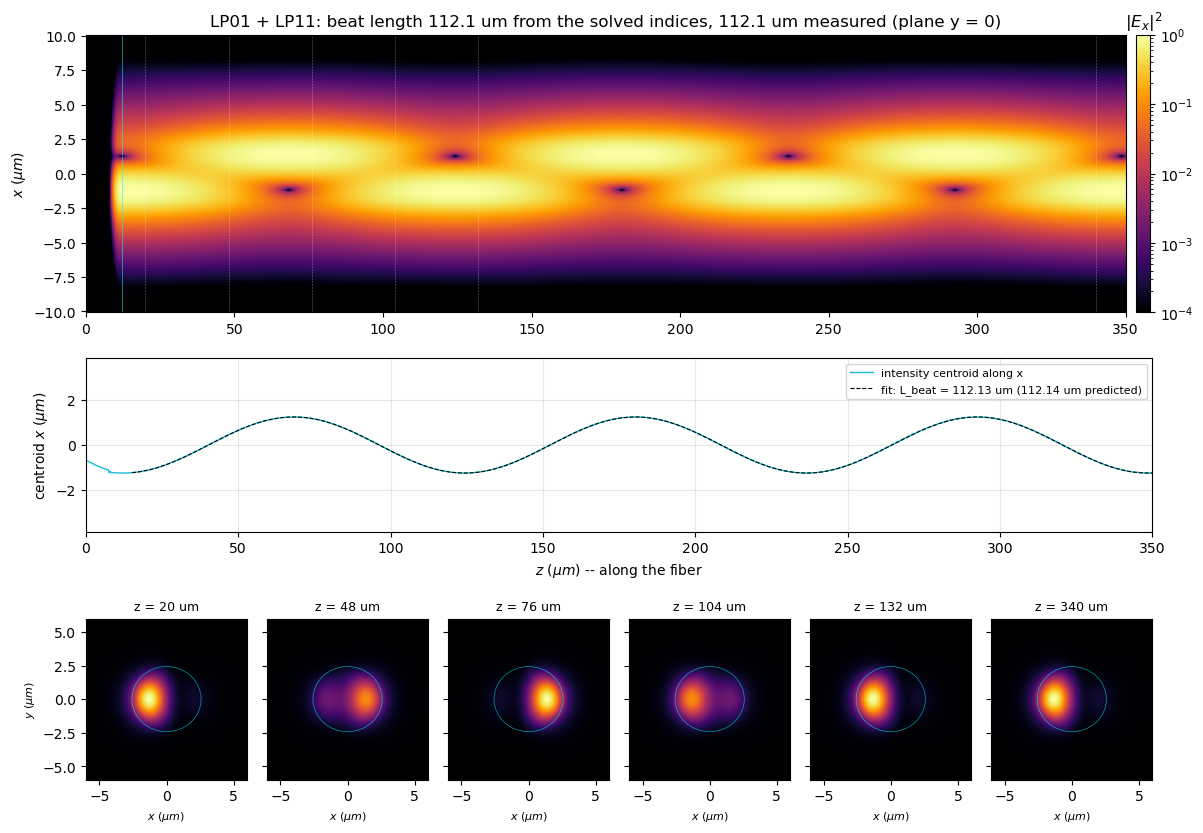

In [11]:
# LP01 is even in x and LP11 odd, so their interference moves the intensity centroid
# along x as cos(2*pi*(z - z0)/L_beat) while the intensity on the axis itself, where LP11
# vanishes, stays flat. Fitting the centroid over the whole length reads the beat length
# out of the field; every point counts, which matters because the beat length is a
# difference of two nearly equal indices and amplifies whatever error each one carries.
ex = axial_field(beat)
x, z = coordinates(ex)
intensity = np.abs(ex) ** 2
centroid = (intensity * x[:, None]).sum(axis=0) / intensity.sum(axis=0)
keep = z > z_clear
_swing = lambda zz, L, z0, amp, off: off + amp * np.cos(2 * np.pi * (zz - z0) / L)
_p, _cov = curve_fit(_swing, z[keep], centroid[keep],
                     p0=[L_beat_predicted, z_drive_end, centroid[keep].max(), 0.0], maxfev=40000)
L_beat_measured, L_beat_err = float(_p[0]), float(np.sqrt(np.diag(_cov))[0])
swing_fit = _swing(z[keep], *_p)
swing_residual = float(np.sqrt(np.mean((centroid[keep] - swing_fit) ** 2)))
on_axis = intensity[np.argmin(np.abs(x)), keep]
print(f"Beat length: {L_beat_predicted:.2f} um from the solved indices, "
      f"{L_beat_measured:.2f} +/- {L_beat_err:.2f} um from the centroid "
      f"({100 * (L_beat_predicted - L_beat_measured) / L_beat_measured:+.2f}% prediction error)")
print(f"  centroid swings +/- {abs(_p[2]):.3f} um about x = {_p[3]:+.3f} um, "
      f"fit residual {swing_residual:.3f} um rms; on-axis intensity ripple "
      f"{(on_axis.max() - on_axis.min()) / on_axis.mean():.2%}")

# Both runs drive LP01 with the same power and phase, so run 2 minus run 1 is LP11 alone.
# What is even in x in that difference is LP01 left over; the phase advance on a lobe gives
# n_11 the way run 1 gave n_01, and the two measured indices predict the beat length a
# second way, independent of the centroid fit.
ex_11 = ex - axial_field(lp01)
even_share = float(np.sum(np.abs(ex_11 + ex_11[::-1, :]) ** 2) / (4 * np.sum(np.abs(ex_11) ** 2)))
lobe = int(np.argmax(np.abs(ex_11[:, keep]).mean(axis=1) * (x > 0)))
neff_11_measured = np.polyfit(z[keep], np.unwrap(np.angle(ex_11[lobe, keep])), 1)[0] * wavelength / (2 * np.pi)
L_beat_from_indices = wavelength / (neff_01_measured - neff_11_measured)
print(f"  run 2 minus run 1: LP01 left over {even_share:.1e} of the energy; LP11 n_eff "
      f"{neff_11_measured:.5f} from its phase advance ({neff_11_measured - neff_11:+.1e} against "
      f"the solved); beat length from the two measured indices {L_beat_from_indices:.2f} um")

with open(f"{OUTPUT_DIR}/results_beat.json", "w") as f:
    json.dump(dict(neff_01=neff_01, neff_11=neff_11, L_beat_predicted=L_beat_predicted,
                   L_beat_measured=L_beat_measured, L_beat_err=L_beat_err,
                   neff_11_measured=neff_11_measured, L_beat_from_indices=L_beat_from_indices,
                   lp01_left_in_difference=even_share,
                   swing_amplitude=abs(float(_p[2])), swing_centre=float(_p[3]),
                   swing_z0=float(_p[1]), swing_residual_rms=swing_residual,
                   axis_intensity_ripple=float((on_axis.max() - on_axis.min()) / on_axis.mean()),
                   e_share={name: beat["modes"][name]["eShare"] for name in ("LP01", "LP11")},
                   iterations=beat["iterations"], seconds=beat["seconds"]), f, indent=1)


def beat_trace(ax, x, z):
    ax.plot(z, centroid, color="tab:cyan", lw=1.0, label="intensity centroid along x")
    ax.plot(z[keep], swing_fit, color="black", lw=0.8, ls="--",
            label=f"fit: L_beat = {L_beat_measured:.2f} um ({L_beat_predicted:.2f} um predicted)")
    ax.set_ylabel(r"centroid $x~(\mu m)$")
    ax.set_ylim(-1.5 * a_x, 1.5 * a_x)


fig = figure(beat, f"LP01 + LP11: beat length {L_beat_predicted:.1f} um from the solved indices, "
             f"{L_beat_measured:.1f} um measured (plane y = 0)", beat_trace)
fig.savefig(f"{OUTPUT_DIR}/mx_fewmode_fiber_beat.png", dpi=200, bbox_inches="tight")
fig.savefig(f"{OUTPUT_DIR}/mx_fewmode_fiber_beat.pdf", bbox_inches="tight")
plt.show()
plt.close("all")

### Coupling in from a thinner, misaligned fiber

  [!] Mode source 'input': linear absorbing layers at the two z ends (35 and 35 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 27 px (4.81 um) per end.


Submitted offset_0.0: project 56c1eba0-880c-40a2-a6c0-22de6ee4efde, version 48330ffd-9b50-44d1-af9b-ac191a335881

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 56c1eba0-880c-40a2-a6c0-22de6ee4efde
  Version   : 48330ffd-9b50-44d1-af9b-ac191a335881
  Command   : ae1f7fc0-297e-43c8-9490-3032e8846099
  Mode      : Maxwell (vectorial)
  Domain    : 115x115x2000 voxels  lambda=1.55 um  dx=0.175 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 169.2 s; Iterations 1494; Residual 9.995011e-07
  input: neff = 1.45678; E energy 99.4% along x, 0.0% along y, 0.6% longitudinal
Offset 0.0 um: input mode neff 1.45678; coupled 0.965 into LP01, 0.000 into LP11 (LP11 fraction 0.000); 0.4% of the field past z = 50 um is neither; centroid against the two-mode model 0.000 um rms


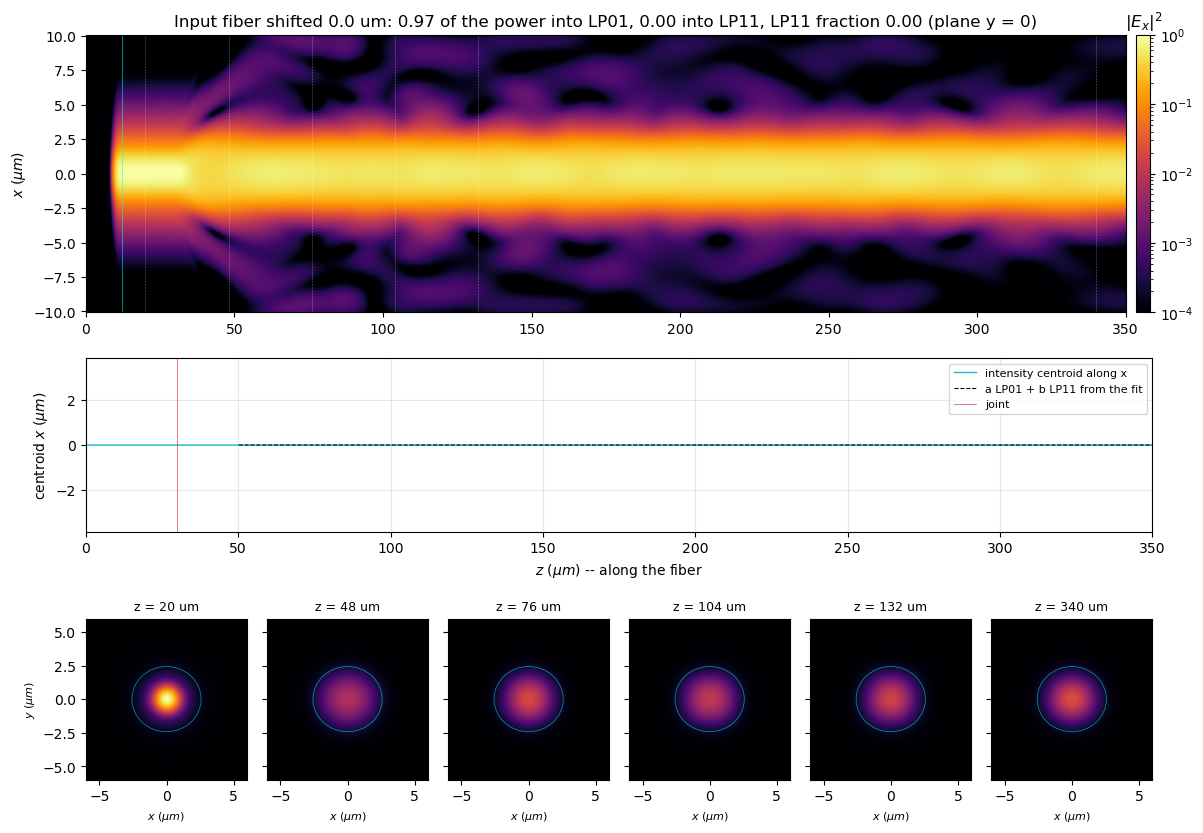

  [!] Mode source 'input': linear absorbing layers at the two z ends (35 and 35 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 27 px (4.81 um) per end.


Submitted offset_1.0: project 0890b3df-51c7-4544-ad9d-e85b3dd24aa3, version c696be4b-62d0-4773-bb47-12ffd3e4d0be

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 0890b3df-51c7-4544-ad9d-e85b3dd24aa3
  Version   : c696be4b-62d0-4773-bb47-12ffd3e4d0be
  Command   : 38487c63-fce9-4ae3-893d-3ebb9b4f9ee0
  Mode      : Maxwell (vectorial)
  Domain    : 115x115x2000 voxels  lambda=1.55 um  dx=0.175 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 176.3 s; Iterations 1514; Residual 9.997533e-07
  input: neff = 1.45674; E energy 99.4% along x, 0.0% along y, 0.6% longitudinal
Offset 1.0 um: input mode neff 1.45674; coupled 0.813 into LP01, 0.150 into LP11 (LP11 fraction 0.156); 0.6% of the field past z = 50 um is neither; centroid against the two-mode model 0.046 um rms


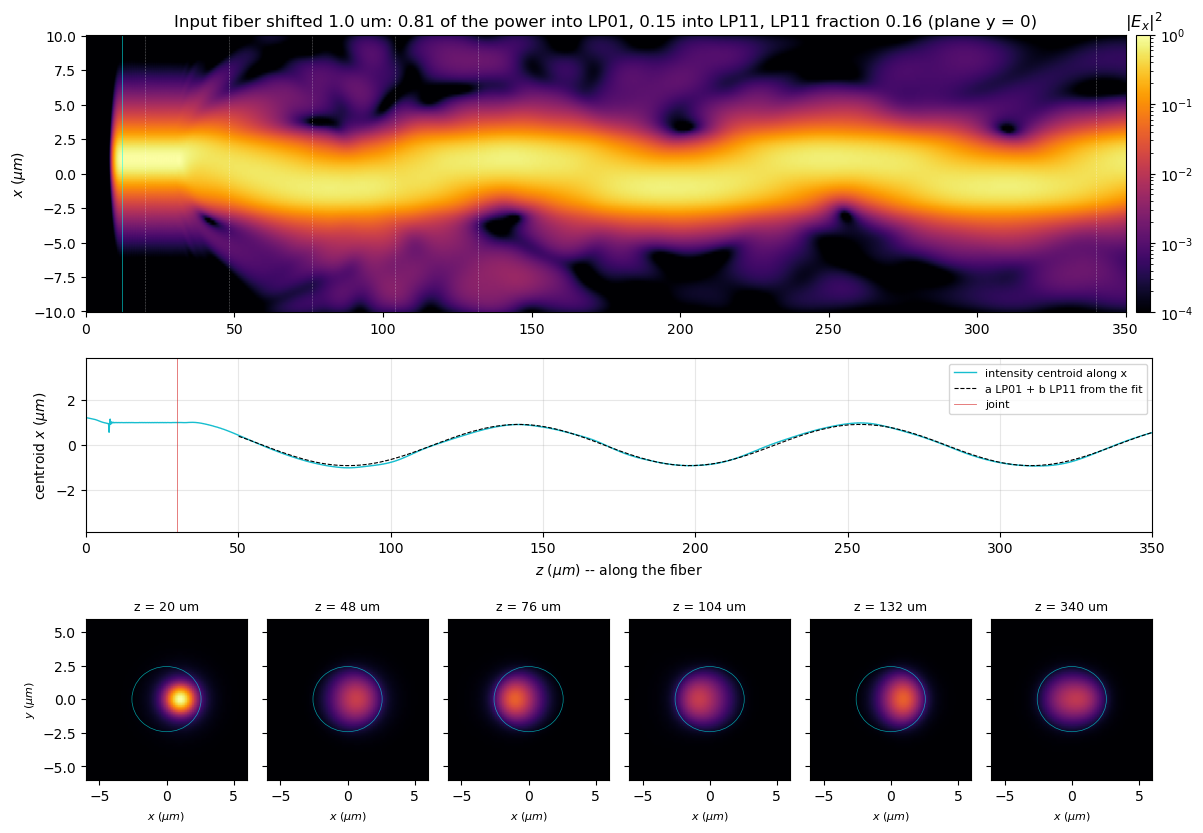

  [!] Mode source 'input': linear absorbing layers at the two z ends (35 and 35 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 27 px (4.81 um) per end.


Submitted offset_2.0: project 1cbc4f19-94b3-4906-af64-e393f19957ca, version 326ee94e-cd40-4da9-8f07-64f97d7dea1c

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 1cbc4f19-94b3-4906-af64-e393f19957ca
  Version   : 326ee94e-cd40-4da9-8f07-64f97d7dea1c
  Command   : 81cd59fa-662e-4d1c-acee-b4ea3ea8c6f0
  Mode      : Maxwell (vectorial)
  Domain    : 115x115x2000 voxels  lambda=1.55 um  dx=0.175 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 160.8 s; Iterations 1287; Residual 9.994977e-07
  input: neff = 1.45674; E energy 99.4% along x, 0.0% along y, 0.6% longitudinal
Offset 2.0 um: input mode neff 1.45674; coupled 0.487 into LP01, 0.329 into LP11 (LP11 fraction 0.403); 5.2% of the field past z = 50 um is neither; centroid against the two-mode model 0.188 um rms


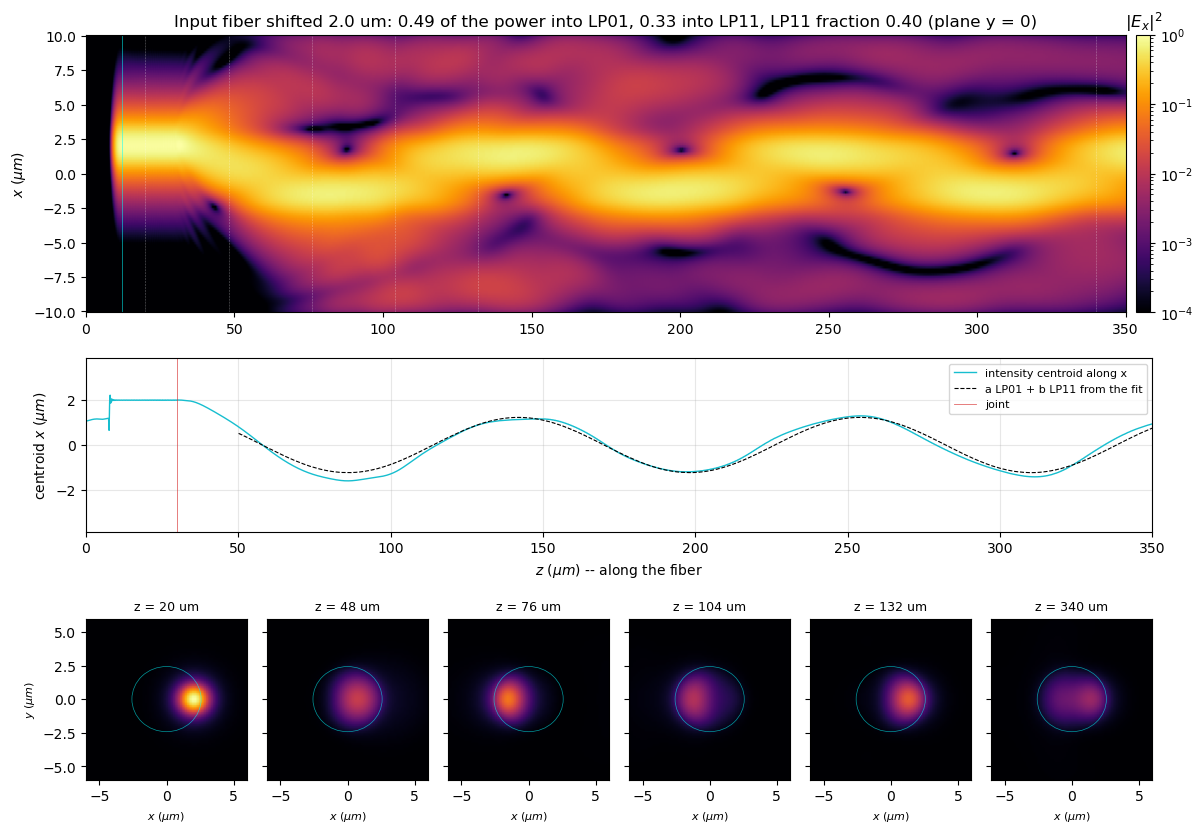

In [12]:
# A single-mode fiber of the same glasses, core radius 1.25 μm (V = 1.5), is butt-joined to
# the few-mode fiber at z_joint with its axis shifted by ``offset`` along x. The cut where
# the drive ends lies inside the input section, so the engine solves and launches the input
# core's own mode; the joint is a real facet and what it radiates is part of the result.
a_in = 1.25                 # input core radius (μm)
z_joint = 30.0              # μm from the input face, 18 μm past the drive end
offsets = [0.0, 1.0, 2.0]   # shift of the input core along x (μm)
k_joint = int(round(z_joint / pixel_size))
z_fit = z_joint + 20.0      # fits start here, past the light the joint throws into the cladding


def joined_fiber(offset):
    """The fine-grid core stack: the input core up to the joint, the few-mode core after."""
    return np.concatenate([extrude(core_layer(a_in, a_in, offset), k_joint),
                           extrude(fiber_layer, nz - k_joint)], axis=2)


# Past the joint the field is a*LP01 + b*LP11 plus whatever the joint radiated. Run 1 is the
# LP01 field at unit power and run 2 minus run 1 the LP11 field at unit power, so a and b
# come from a linear least-squares fit of the new field onto those two over the fit window:
# |a|^2 and |b|^2 are then the powers coupled into each mode as a share of the launched
# power, and what the fit leaves over is light that is neither. The intensity centroid is
# only compared with the two-mode model here, not fitted: it also weighs the light the
# joint radiated, which spreads so slowly along the fiber that the box still holds a few
# percent of it 300 μm on.
e_01 = axial_field(lp01)
e_11 = axial_field(beat) - e_01
window = z > z_fit


def decompose(ex3):
    basis = np.stack([e_01[:, window].ravel(), e_11[:, window].ravel()], axis=1)
    (a, b), *_ = np.linalg.lstsq(basis, ex3[:, window].ravel(), rcond=None)
    model = a * e_01 + b * e_11
    leftover = float(np.sum(np.abs(ex3 - model)[:, window] ** 2) / np.sum(np.abs(ex3[:, window]) ** 2))
    return a, b, model, leftover


def centroid_of(ex3):
    intensity = np.abs(ex3) ** 2
    return (intensity * x[:, None]).sum(axis=0) / intensity.sum(axis=0)


coupling = {}
for offset in offsets:
    tag = f"offset_{offset:.1f}"
    run = solve(tag, [fiber_mode("input", 0)], joined_fiber(offset))
    neff_in = run["modes"]["input"]["neff"]["re"]
    ex3 = axial_field(run)
    a, b, model, leftover = decompose(ex3)
    p01, p11 = abs(a) ** 2, abs(b) ** 2
    fraction = p11 / (p01 + p11)
    centroid3, centroid_model = centroid_of(ex3), centroid_of(model)
    centroid_rms = float(np.sqrt(np.mean((centroid3 - centroid_model)[window] ** 2)))
    result = dict(offset=offset, neff_input=neff_in, p_lp01=float(p01), p_lp11=float(p11),
                  lp11_fraction=float(fraction), leftover=leftover, centroid_rms=centroid_rms,
                  e_share=run["modes"]["input"]["eShare"], iterations=run["iterations"],
                  seconds=run["seconds"])
    print(f"Offset {offset:.1f} um: input mode neff {neff_in:.5f}; coupled {p01:.3f} into LP01, "
          f"{p11:.3f} into LP11 (LP11 fraction {fraction:.3f}); {leftover:.1%} of the field past "
          f"z = {z_fit:.0f} um is neither; centroid against the two-mode model {centroid_rms:.3f} um rms")
    coupling[offset] = result
    with open(f"{OUTPUT_DIR}/results_{tag}.json", "w") as f:
        json.dump(result, f, indent=1)

    def offset_trace(ax, x, z, c=centroid3, m=centroid_model):
        ax.plot(z, c, color="tab:cyan", lw=1.0, label="intensity centroid along x")
        ax.plot(z[window], m[window], color="black", lw=0.8, ls="--",
                label="a LP01 + b LP11 from the fit")
        ax.axvline(z_joint, color="tab:red", lw=0.6, alpha=0.7, label="joint")
        ax.set_ylabel(r"centroid $x~(\mu m)$")
        ax.set_ylim(-1.5 * a_x, 1.5 * a_x)

    fig = figure(run, f"Input fiber shifted {offset:.1f} um: {p01:.2f} of the power into LP01, "
                 f"{p11:.2f} into LP11, LP11 fraction {fraction:.2f} (plane y = 0)", offset_trace)
    fig.savefig(f"{OUTPUT_DIR}/mx_fewmode_fiber_{tag}.png", dpi=200, bbox_inches="tight")
    fig.savefig(f"{OUTPUT_DIR}/mx_fewmode_fiber_{tag}.pdf", bbox_inches="tight")
    plt.show()
    plt.close("all")

### What the joint does, offset by offset

In [13]:
print(f"{'offset (um)':>12s} {'into LP01':>10s} {'into LP11':>10s} {'LP11 fraction':>14s} "
      f"{'neither':>8s} {'centroid vs model (um rms)':>27s}")
for offset, r in coupling.items():
    print(f"{offset:>12.1f} {r['p_lp01']:>10.3f} {r['p_lp11']:>10.3f} {r['lp11_fraction']:>14.3f} "
          f"{r['leftover']:>8.1%} {r['centroid_rms']:>27.3f}")

 offset (um)  into LP01  into LP11  LP11 fraction  neither  centroid vs model (um rms)
         0.0      0.965      0.000          0.000     0.4%                       0.000
         1.0      0.813      0.150          0.156     0.6%                       0.046
         2.0      0.487      0.329          0.403     5.2%                       0.188
